# **Bank Marketing Campaign: EDA & Predictive Modeling**
### Will a customer subscribe to a term deposit — and who should the bank call next?

**Dataset:** [Bank Marketing Dataset (Kaggle)](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset)

This project analyzes direct marketing (phone call) campaign data from a Portuguese banking institution. The goal is twofold:
1. **Understand** which customer and campaign characteristics drive term deposit subscriptions (EDA)
2. **Predict** subscription likelihood ahead of a call, so the bank can prioritize its call list (Machine Learning)

**Project structure:**
1. Data Cleaning & Missing Value Treatment
2. Statistical Summary
3. Feature Engineering & Leakage Check
4. Univariate Analysis
5. Bivariate Analysis
6. Multivariate Analysis
7. Outlier Treatment
8. Preprocessing for Modeling
9. Baseline Predictive Modeling (Logistic Regression, Random Forest, XGBoost)
10. Feature Importance
11. Business Recommendations & Executive Summary

**Tech stack:** Python, pandas, NumPy, seaborn/matplotlib, scikit-learn, XGBoost

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('bank.csv')

In [3]:
print("Data shape :")
print(f"Rows:{df.shape[0]},Columns:{df.shape[1]}")
print("\n First five rows:")
df.head()

Data shape :
Rows:11162,Columns:17

 First five rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [4]:
print("\n Data Info")
print(df.info())


 Data Info
<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB
None


# **Column Types:**
*   **Numerical**: age,balance,duration,campaign,pdays,previous,day
*  **Categorical**: job,marital,education,default,housing,loan,contact,month,poutcome,deposit

In [5]:
print("Checking missing values ...")
print(df.isnull().sum())

Checking missing values ...
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


# **STATISTICAL SUMMARY**

In [6]:
print("Description of data:")
print(df.describe())

Description of data:
                age       balance           day      duration      campaign  \
count  11162.000000  11162.000000  11162.000000  11162.000000  11162.000000   
mean      41.231948   1528.538524     15.658036    371.993818      2.508421   
std       11.913369   3225.413326      8.420740    347.128386      2.722077   
min       18.000000  -6847.000000      1.000000      2.000000      1.000000   
25%       32.000000    122.000000      8.000000    138.000000      1.000000   
50%       39.000000    550.000000     15.000000    255.000000      2.000000   
75%       49.000000   1708.000000     22.000000    496.000000      3.000000   
max       95.000000  81204.000000     31.000000   3881.000000     63.000000   

              pdays      previous  
count  11162.000000  11162.000000  
mean      51.330407      0.832557  
std      108.758282      2.292007  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%       20.75

--- Count of 'unknown' in each column ---

--- Real Missing Value Count ---
age             0
job            70
marital         0
education     497
default         0
balance         0
housing         0
loan            0
contact      2346
day             0
month           0
duration        0
campaign        0
pdays           0
previous        0
poutcome     8326
deposit         0
dtype: int64


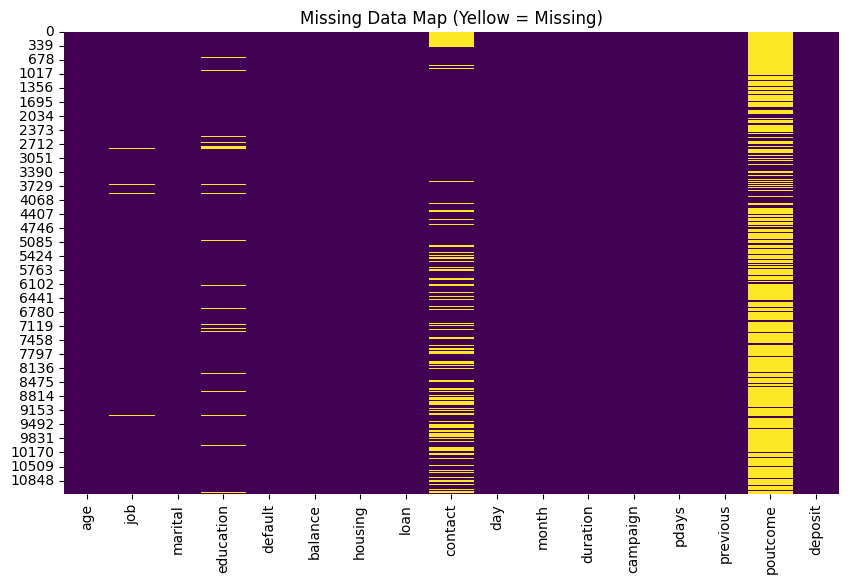

In [7]:

print("--- Count of 'unknown' in each column ---")
for col in df.columns:
    if df[col].dtype == 'object':
        count = (df[col] == 'unknown').sum()
        if count > 0:
            print(f"{col}: {count}")

df.replace('unknown', np.nan, inplace=True)
print("\n--- Real Missing Value Count ---")
print(df.isnull().sum())

plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Data Map (Yellow = Missing)")
plt.show()

In [8]:
print(df['poutcome'].unique())

# BUG FIX: by this point 'unknown' was already converted to NaN in the previous cell
# (global df.replace('unknown', np.nan)), so .replace('unknown', ...) here was a silent no-op.
# Use fillna() instead so these categories are actually recoded.
df['poutcome'] = df['poutcome'].fillna('not_contacted')

df['contact'] = df['contact'].fillna('other_method')

print("\nAfter fix -- remaining NaNs in poutcome:", df['poutcome'].isnull().sum())
print("After fix -- remaining NaNs in contact:", df['contact'].isnull().sum())

<StringArray>
[nan, 'other', 'failure', 'success']
Length: 4, dtype: str

After fix -- remaining NaNs in poutcome: 0
After fix -- remaining NaNs in contact: 0


In [9]:
df.head(-5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,other_method,5,may,1042,1,-1,0,not_contacted,yes
1,56,admin.,married,secondary,no,45,no,no,other_method,5,may,1467,1,-1,0,not_contacted,yes
2,41,technician,married,secondary,no,1270,yes,no,other_method,5,may,1389,1,-1,0,not_contacted,yes
3,55,services,married,secondary,no,2476,yes,no,other_method,5,may,579,1,-1,0,not_contacted,yes
4,54,admin.,married,tertiary,no,184,no,no,other_method,5,may,673,2,-1,0,not_contacted,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11152,34,housemaid,married,secondary,no,390,yes,no,cellular,15,jul,659,3,-1,0,not_contacted,no
11153,43,admin.,single,secondary,no,35,no,no,telephone,9,nov,208,1,-1,0,not_contacted,no
11154,52,technician,married,tertiary,no,523,yes,yes,cellular,8,jul,113,1,-1,0,not_contacted,no
11155,35,blue-collar,married,secondary,no,80,yes,yes,cellular,21,nov,38,2,172,2,failure,no


In [10]:

df['was_contacted_previously'] = df['pdays'].apply(lambda x: 0 if x == -1 else 1)

print("--- Checking the Transformation.. ---")
print(df[['pdays', 'was_contacted_previously']].head(10))
print("\n--- Distribution ---")
print(df['was_contacted_previously'].value_counts())

--- Checking the Transformation.. ---
   pdays  was_contacted_previously
0     -1                         0
1     -1                         0
2     -1                         0
3     -1                         0
4     -1                         0
5     -1                         0
6     -1                         0
7     -1                         0
8     -1                         0
9     -1                         0

--- Distribution ---
was_contacted_previously
0    8324
1    2838
Name: count, dtype: int64


In [11]:

df['target_temp'] = df['deposit'].map({'yes': 1, 'no': 0})
print("Correlation with Target:", df['duration'].corr(df['target_temp']))

df.drop(columns=['duration', 'target_temp'], inplace=True, errors='ignore')

print("Duration column dropped. Leakage fixed.")

Correlation with Target: 0.4519193608425833
Duration column dropped. Leakage fixed.


In [12]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,deposit,was_contacted_previously
0,59,admin.,married,secondary,no,2343,yes,no,other_method,5,may,1,-1,0,not_contacted,yes,0
1,56,admin.,married,secondary,no,45,no,no,other_method,5,may,1,-1,0,not_contacted,yes,0
2,41,technician,married,secondary,no,1270,yes,no,other_method,5,may,1,-1,0,not_contacted,yes,0
3,55,services,married,secondary,no,2476,yes,no,other_method,5,may,1,-1,0,not_contacted,yes,0
4,54,admin.,married,tertiary,no,184,no,no,other_method,5,may,2,-1,0,not_contacted,yes,0


## **Univariate Analysis:**
What is it? It simply means analyzing one variable (or column) of data at a time, without worrying about the others.

Why do we use it?
To Check Patterns: You look at the shape of the data to see where most values are (the average) and how spread out they are.

To Find Problems: It helps you spot errors like missing data, lopsided patterns (skewness), or weird extreme values (outliers).

How to Analyze Numerical Columns (5 Steps)
1. Check the Stats Calculate the basics like the Mean (average), Median (middle), and Standard Deviation (spread). This gives you a quick summary of what the data looks like.

2. Make Charts Draw pictures to see the data better.

Use Histograms or Density Plots to see the shape.

Use Box Plots to spot outliers.

3. Find Outliers Look for values that are very far away from the rest. You need to decide: Is this a mistake (delete it) or real data (keep it)?.

4. Check Skewness See if the data leans too much to the left or right (skewed). If it's too lopsided, you might need to fix it using math tricks (transformations).

5. Conclusion Summarize what you found and decide your next move for the analysis.

In [13]:
def analyze_numerical_columns(df, columns):
    for col in columns:
        print(f"--- Analyzing: {col} ---")

        # 1. Calculate Stats
        desc_stats = df[col].describe()
        skew_val = df[col].skew()

        missing_count = df[col].isnull().sum()
        missing_percent = (missing_count / len(df)) * 100

        print(f"Mean: {desc_stats['mean']:.2f} | Median: {desc_stats['50%']:.2f}")
        print(f"Skewness: {skew_val:.2f}")
        print(f"Missing Values: {missing_count} ({missing_percent:.2f}%)")

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))


        sns.histplot(df[col], kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f'Distribution of {col}')

        # Box Plot
        sns.boxplot(x=df[col], ax=axes[1], color='orange')
        axes[1].set_title(f'Box Plot of {col}')

        plt.show()
        print("\n" + "="*50 + "\n")

--- Analyzing: age ---
Mean: 41.23 | Median: 39.00
Skewness: 0.86
Missing Values: 0 (0.00%)


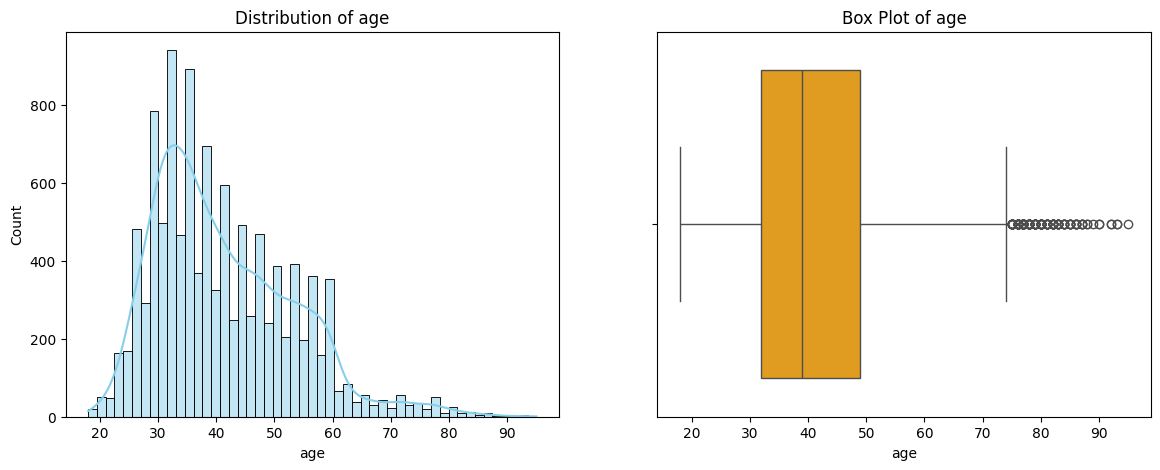



--- Analyzing: balance ---
Mean: 1528.54 | Median: 550.00
Skewness: 8.22
Missing Values: 0 (0.00%)


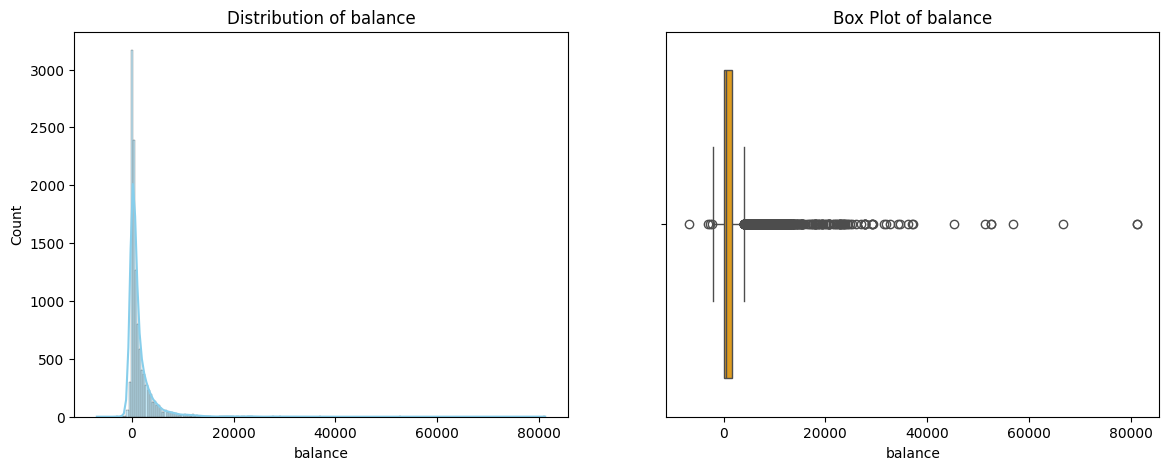



--- Analyzing: campaign ---
Mean: 2.51 | Median: 2.00
Skewness: 5.55
Missing Values: 0 (0.00%)


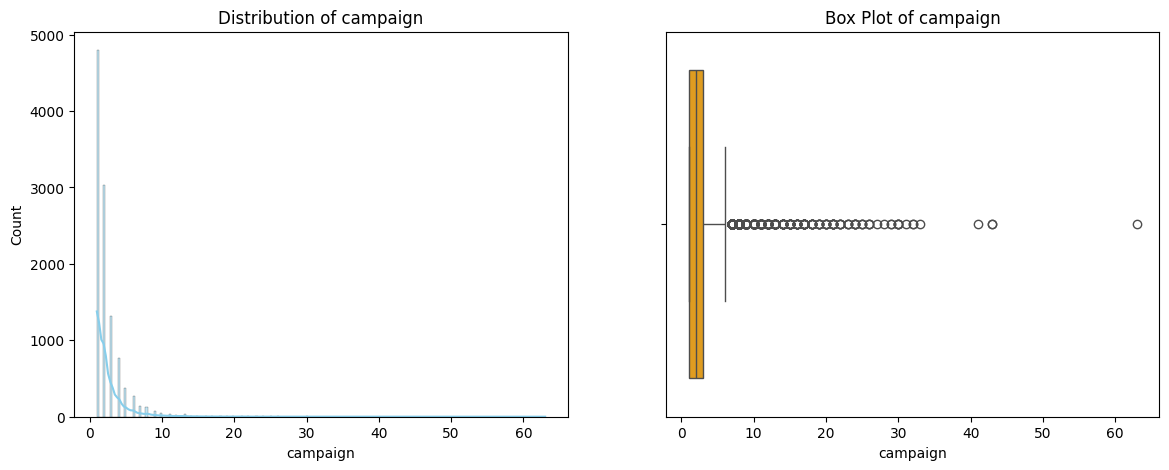



--- Analyzing: pdays ---
Mean: 51.33 | Median: -1.00
Skewness: 2.45
Missing Values: 0 (0.00%)


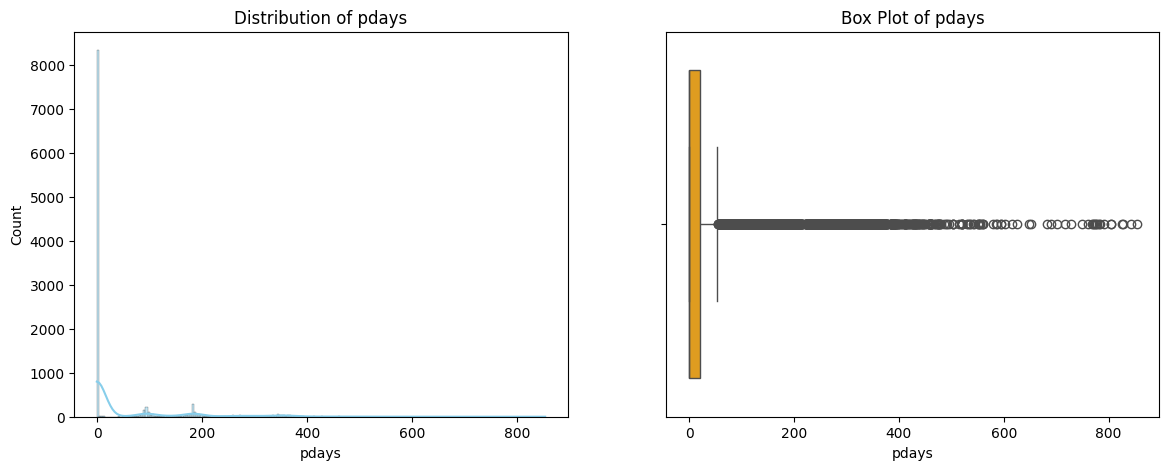



--- Analyzing: previous ---
Mean: 0.83 | Median: 0.00
Skewness: 7.34
Missing Values: 0 (0.00%)


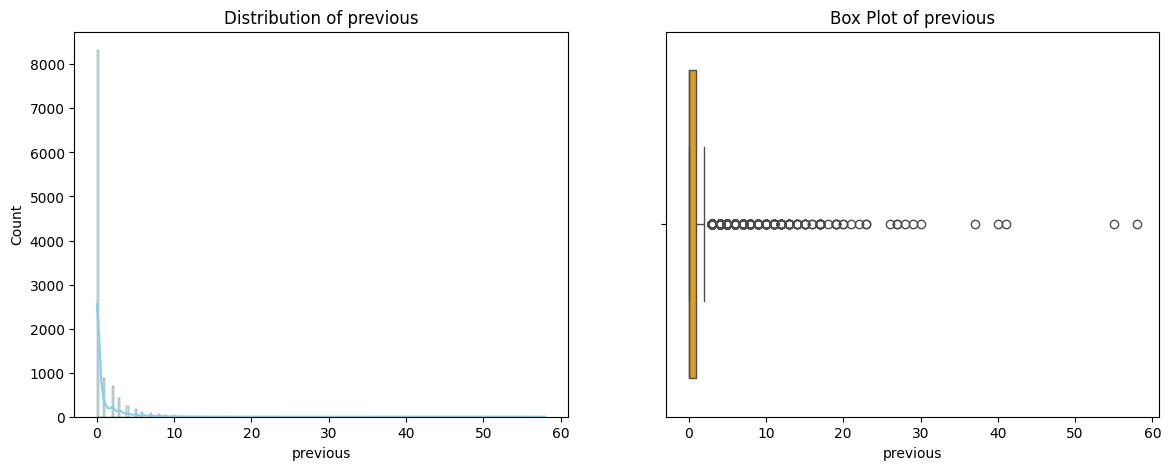



--- Analyzing: day ---
Mean: 15.66 | Median: 15.00
Skewness: 0.11
Missing Values: 0 (0.00%)


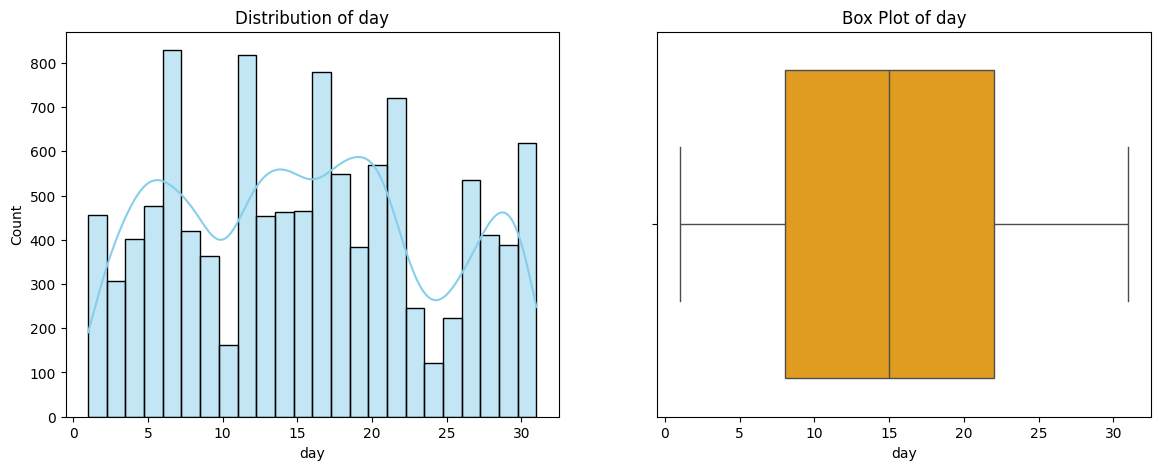

In [14]:

 analyze_numerical_columns(df, ['age', 'balance', 'campaign', 'pdays', 'previous', 'day'])

How to Analyze Categorical Columns (4 Steps)
1. Check the Counts (Descriptive Stats) Simply count how many times each category appears. This tells you which categories are popular and which are rare.

2. Make Charts (Visualizations) Draw pictures to see the data clearly.

Use Count Plots (Bar Charts) or Pie Charts.

These help you spot patterns or weird anomalies instantly.

3. Find Missing Data Check if any data is empty. You need to decide:

Fill it in (Impute), or

Delete it (Exclude).

4. Conclusion Summarize what you found and decide your next move for the analysis.

In [15]:


def analyze_categorical_columns(df, columns):
    for col in columns:
        print(f"--- Analyzing: {col} ---")

        # 1. Data Prep
        counts = df[col].value_counts()
        percent = df[col].value_counts(normalize=True) * 100

        # 2. Print Written Result
        top_cat = counts.index[0]
        top_val = percent.iloc[0]
        print(f"Top category: '{top_cat}' ({top_val:.1f}%)\n")

        # 3. Visualization Logic
        # If we have too many categories, a Pie chart is messy. Switch to Bar.
        if len(counts) > 5:
            plt.figure(figsize=(10, 6))
            # Modified line to address the FutureWarning
            ax = sns.barplot(x=counts.values, y=counts.index, hue=counts.index, palette='pastel', legend=False)

            # Add percentage text to the end of bars
            for i, p in enumerate(ax.patches):
                percentage = f'{percent.iloc[i]:.1f}%'
                x = p.get_width()
                y = p.get_y() + p.get_height() / 2
                ax.annotate(percentage, (x, y), va='center', ha='left', xytext=(5, 0), textcoords='offset points')

            plt.title(f'Distribution of {col} (Bar Chart)')
            plt.xlabel('Count')
            sns.despine() # Removes top and right borders for a cleaner look
            plt.show()

        else:
            plt.figure(figsize=(8, 8))
            plt.pie(counts, labels=counts.index, autopct='%1.1f%%',
                    startangle=140, colors=sns.color_palette('pastel'))
            plt.title(f'Percentage Distribution of {col}')
            plt.show()

        print("\n" + "="*50 + "\n")

--- Analyzing: job ---
Top category: 'management' (23.1%)



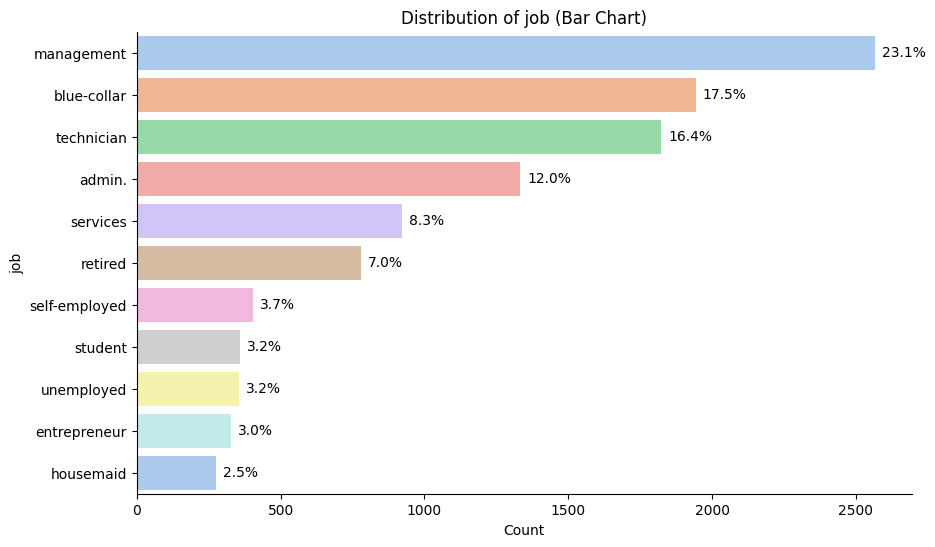



--- Analyzing: marital ---
Top category: 'married' (56.9%)



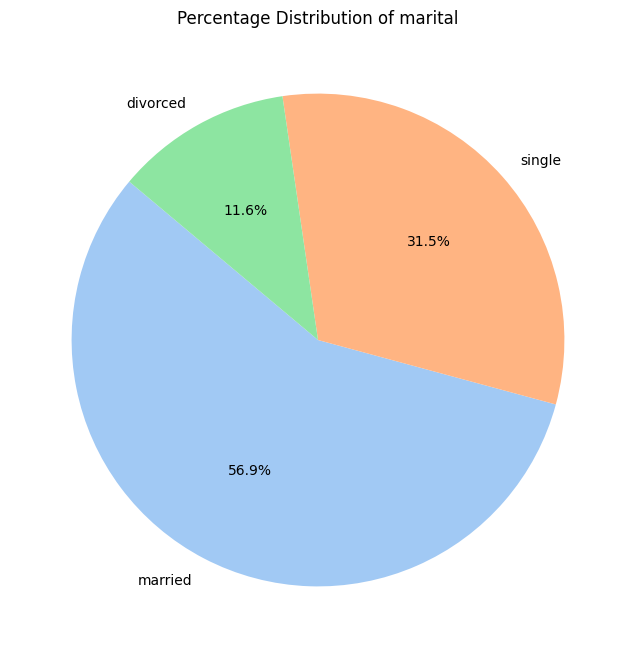



--- Analyzing: education ---
Top category: 'secondary' (51.3%)



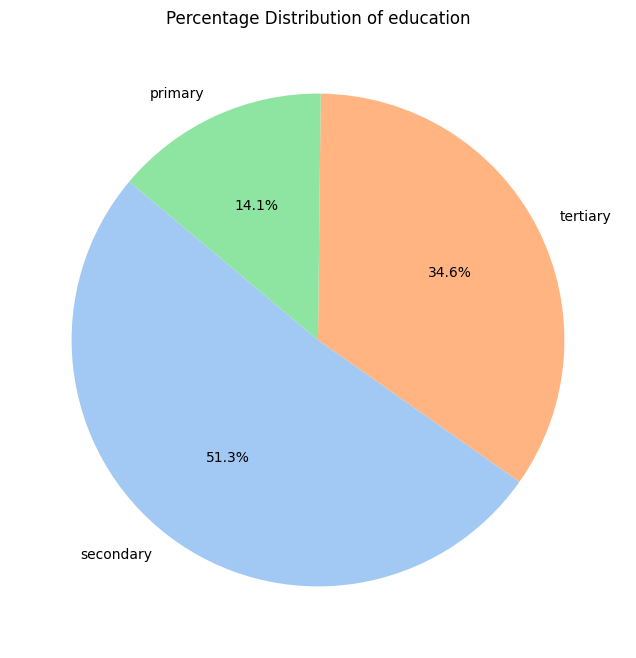



--- Analyzing: default ---
Top category: 'no' (98.5%)



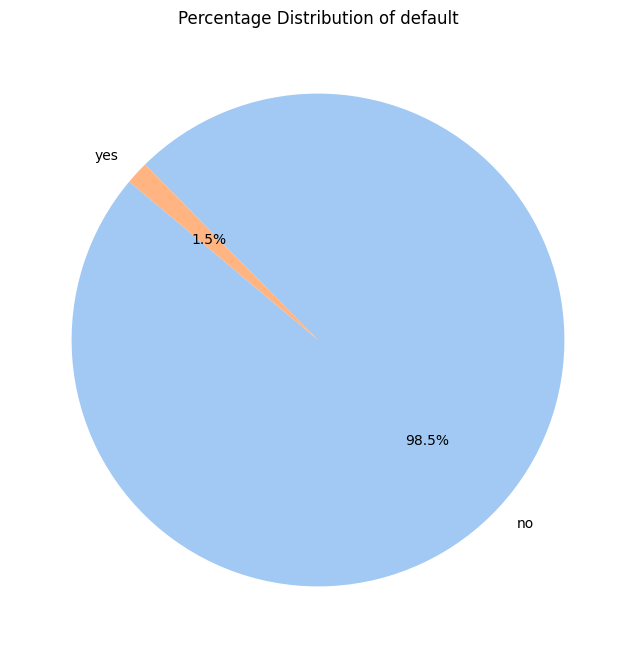



--- Analyzing: housing ---
Top category: 'no' (52.7%)



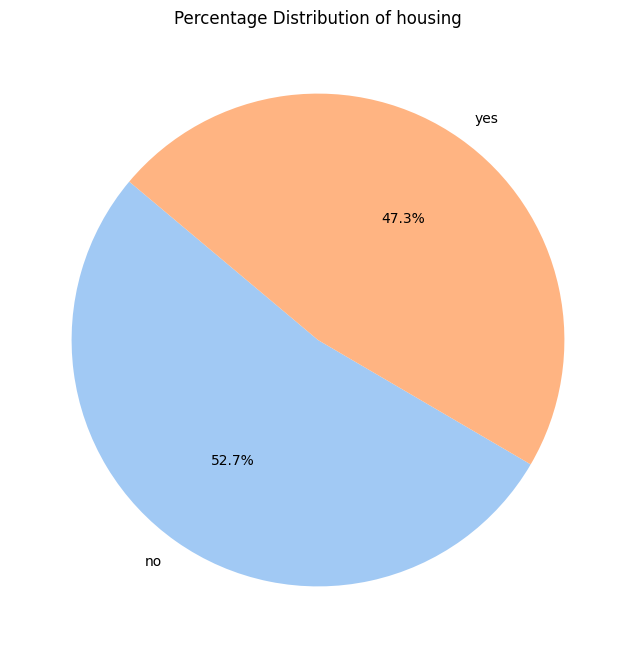



--- Analyzing: loan ---


Top category: 'no' (86.9%)



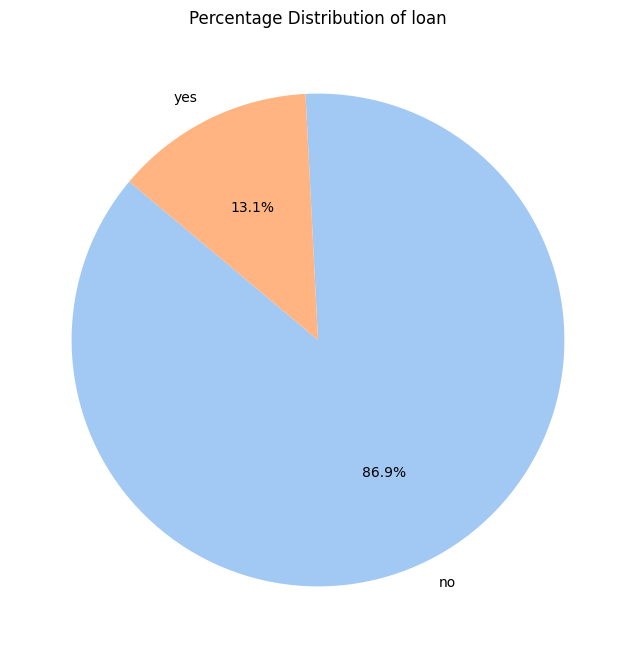



--- Analyzing: contact ---
Top category: 'cellular' (72.0%)



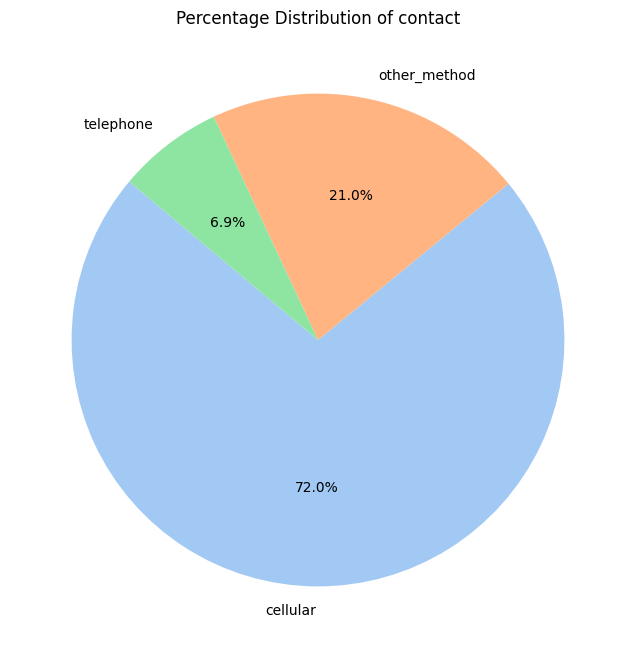



--- Analyzing: month ---
Top category: 'may' (25.3%)



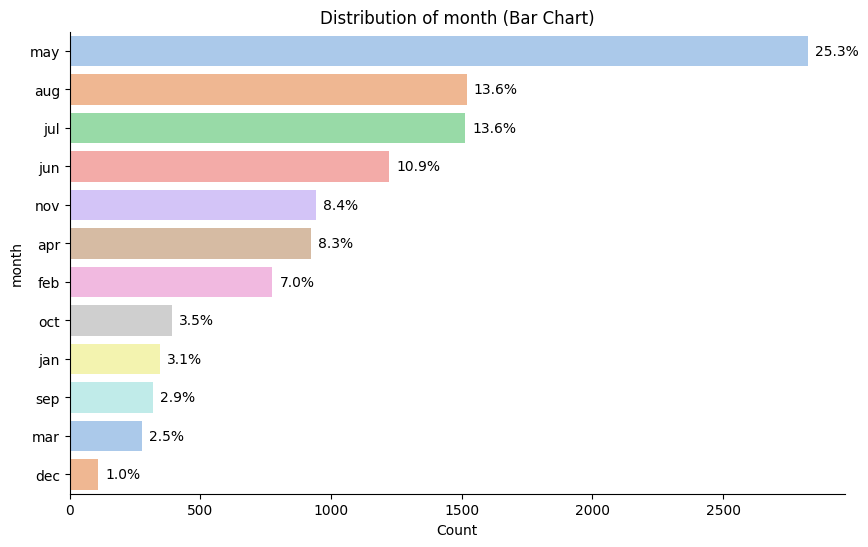



--- Analyzing: poutcome ---


Top category: 'not_contacted' (74.6%)



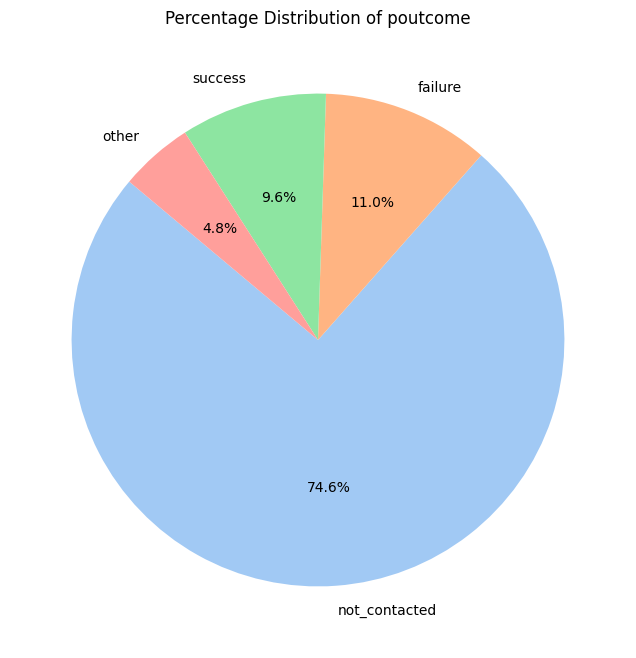



--- Analyzing: deposit ---
Top category: 'no' (52.6%)



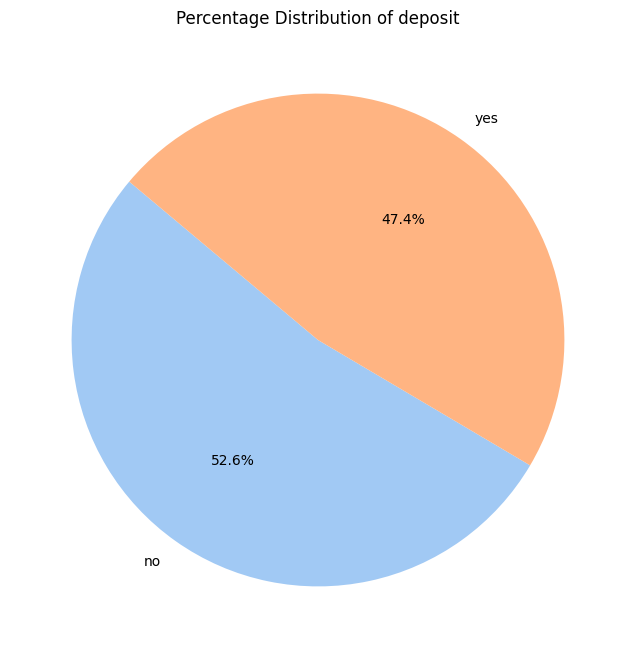

In [16]:
categorical_columns = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
analyze_categorical_columns(df, categorical_columns)

**Conclusion: Univariate Analysis (Categorical Columns)**
1. Balanced Target

Observation: Our target column deposit is split almost evenly (53% No vs 47% Yes).


2. The Problematic Columns

default (Credit Default):

Issue: 98.5% of people said "No".


poutcome (Previous Outcome):

Issue: 74.6% are "unknown".

3. Seasonality Found

month: The month of May is by far the busiest (25%). This suggests the bank campaigns are heavily seasonal (likely Spring/Summer).


Steps for Bivariate Analysis (Comparing 2 Columns)
1. Pick Two Columns Select the two variables you want to compare to see if they are related

2. Identify the Relationship Type The method we use depends on what kind of data you have:

Number vs. Number

Visuals: Use Scatter Plots or 2D Histograms to see patterns.

Math: Calculate the Correlation Coefficient to see how strongly they are linked.

Number vs. Category (e.g., Salary vs. Gender)

Visuals: Use Box Plots, Bar Plots, or Violin Plots.

Goal: Compare the average (or distribution) of the number across the different groups.

Category vs. Category

Visuals: Use Heatmaps or Stacked Bar Charts.

Goal: See how often these two categories overlap.

3. Write Conclusions

In [17]:
def perform_bivariate_analysis(df, target_col='deposit'):
    """
    Runs Bivariate Analysis with AUTOMATED WRITTEN INSIGHTS.
    """

    # --- 1. NUMERICAL vs NUMERICAL (Correlation) ---
    print(f"\n{'='*20} 1. Correlation Heatmap {'='*20}")
    numeric_df = df.select_dtypes(include=['number'])

    if not numeric_df.empty:
        # Plot
        plt.figure(figsize=(10, 8))
        corr_matrix = numeric_df.corr()
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
        plt.title('Correlation Heatmap')
        plt.show()

        # Written Insight: Find strongest correlation
        print(">>> WRITTEN INSIGHT:")
        pairs = corr_matrix.unstack().sort_values(ascending=False)
        top_pair = pairs[pairs < 1.0].idxmax()
        top_val = pairs[pairs < 1.0].max()
        print(f"The strongest correlation is between {top_pair} ({top_val:.2f}).")

    else:
        print("No numerical columns found.")

    # --- 2. NUMERICAL vs TARGET (Box Plots) ---
    print(f"\n{'='*20} 2. Numerical vs Target (Box Plots) {'='*20}")
    num_cols = df.select_dtypes(include=['number']).columns.tolist()

    if num_cols:
        # Layout logic
        n_rows = (len(num_cols) + 1) // 2
        fig, axes = plt.subplots(n_rows, 2, figsize=(15, 5 * n_rows))
        axes = axes.flatten()

        for i, col in enumerate(num_cols):
            # FIXED CODE: Added hue=... and legend=False to stop warnings
            sns.boxplot(x=df[target_col], y=df[col], hue=df[target_col], palette='pastel', legend=False, ax=axes[i])
            axes[i].set_title(f'{col} Distribution by {target_col}')

            # Written Insight: Compare Means
            try:
                means = df.groupby(target_col)[col].mean()
                diff = means.max() - means.min()
                print(f"-> {col}: Gap of {diff:.2f} between the averages.")
            except:
                pass

        # Cleanup empty plots
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout()
        plt.show()
    print(f"\n{'='*20} 3. Categorical vs Target (Stacked Bars) {'='*20}")
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    if target_col in cat_cols:
        cat_cols.remove(target_col)

    for col in cat_cols:
        # Cross Tabulation
        cross_tab = pd.crosstab(df[col], df[target_col], normalize='index')


        try:
            success_col = cross_tab.columns[-1] # Grabs the last column (usually 'yes' or 1)
            best_cat = cross_tab[success_col].idxmax()
            best_rate = cross_tab[success_col].max() * 100
            print(f"\n>>> WRITTEN INSIGHT for '{col}':")
            print(f"The best category is '{best_cat}' with a {best_rate:.1f}% success rate.")
        except:
            pass

        # Plot
        cross_tab.plot(kind='bar', stacked=True, figsize=(10, 5), color=['#ff9999','#66b3ff'])
        plt.title(f'Success Rate by {col}')
        plt.ylabel('Proportion')
        plt.legend(title=target_col, bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()


==================== 1. Correlation Heatmap ====================


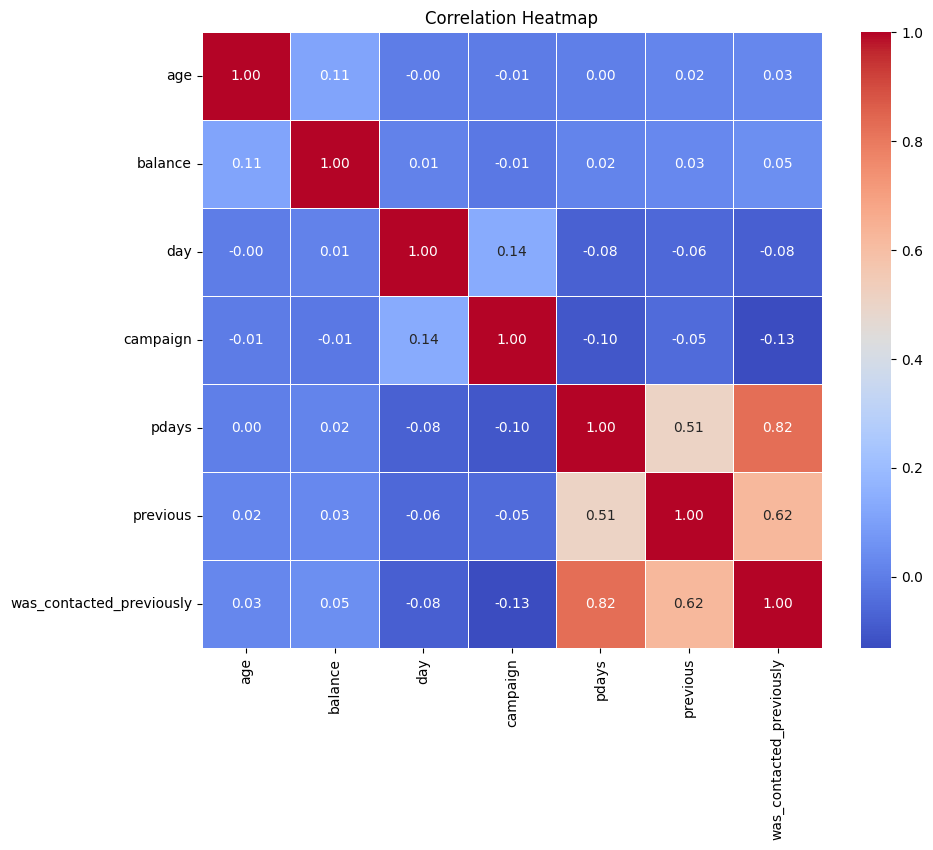

>>> WRITTEN INSIGHT:
The strongest correlation is between ('was_contacted_previously', 'pdays') (0.82).

==================== 2. Numerical vs Target (Box Plots) ====================
-> age: Gap of 0.83 between the averages.
-> balance: Gap of 524.04 between the averages.


-> day: Gap of 0.95 between the averages.
-> campaign: Gap of 0.70 between the averages.
-> pdays: Gap of 33.02 between the averages.
-> previous: Gap of 0.64 between the averages.


-> was_contacted_previously: Gap of 0.20 between the averages.


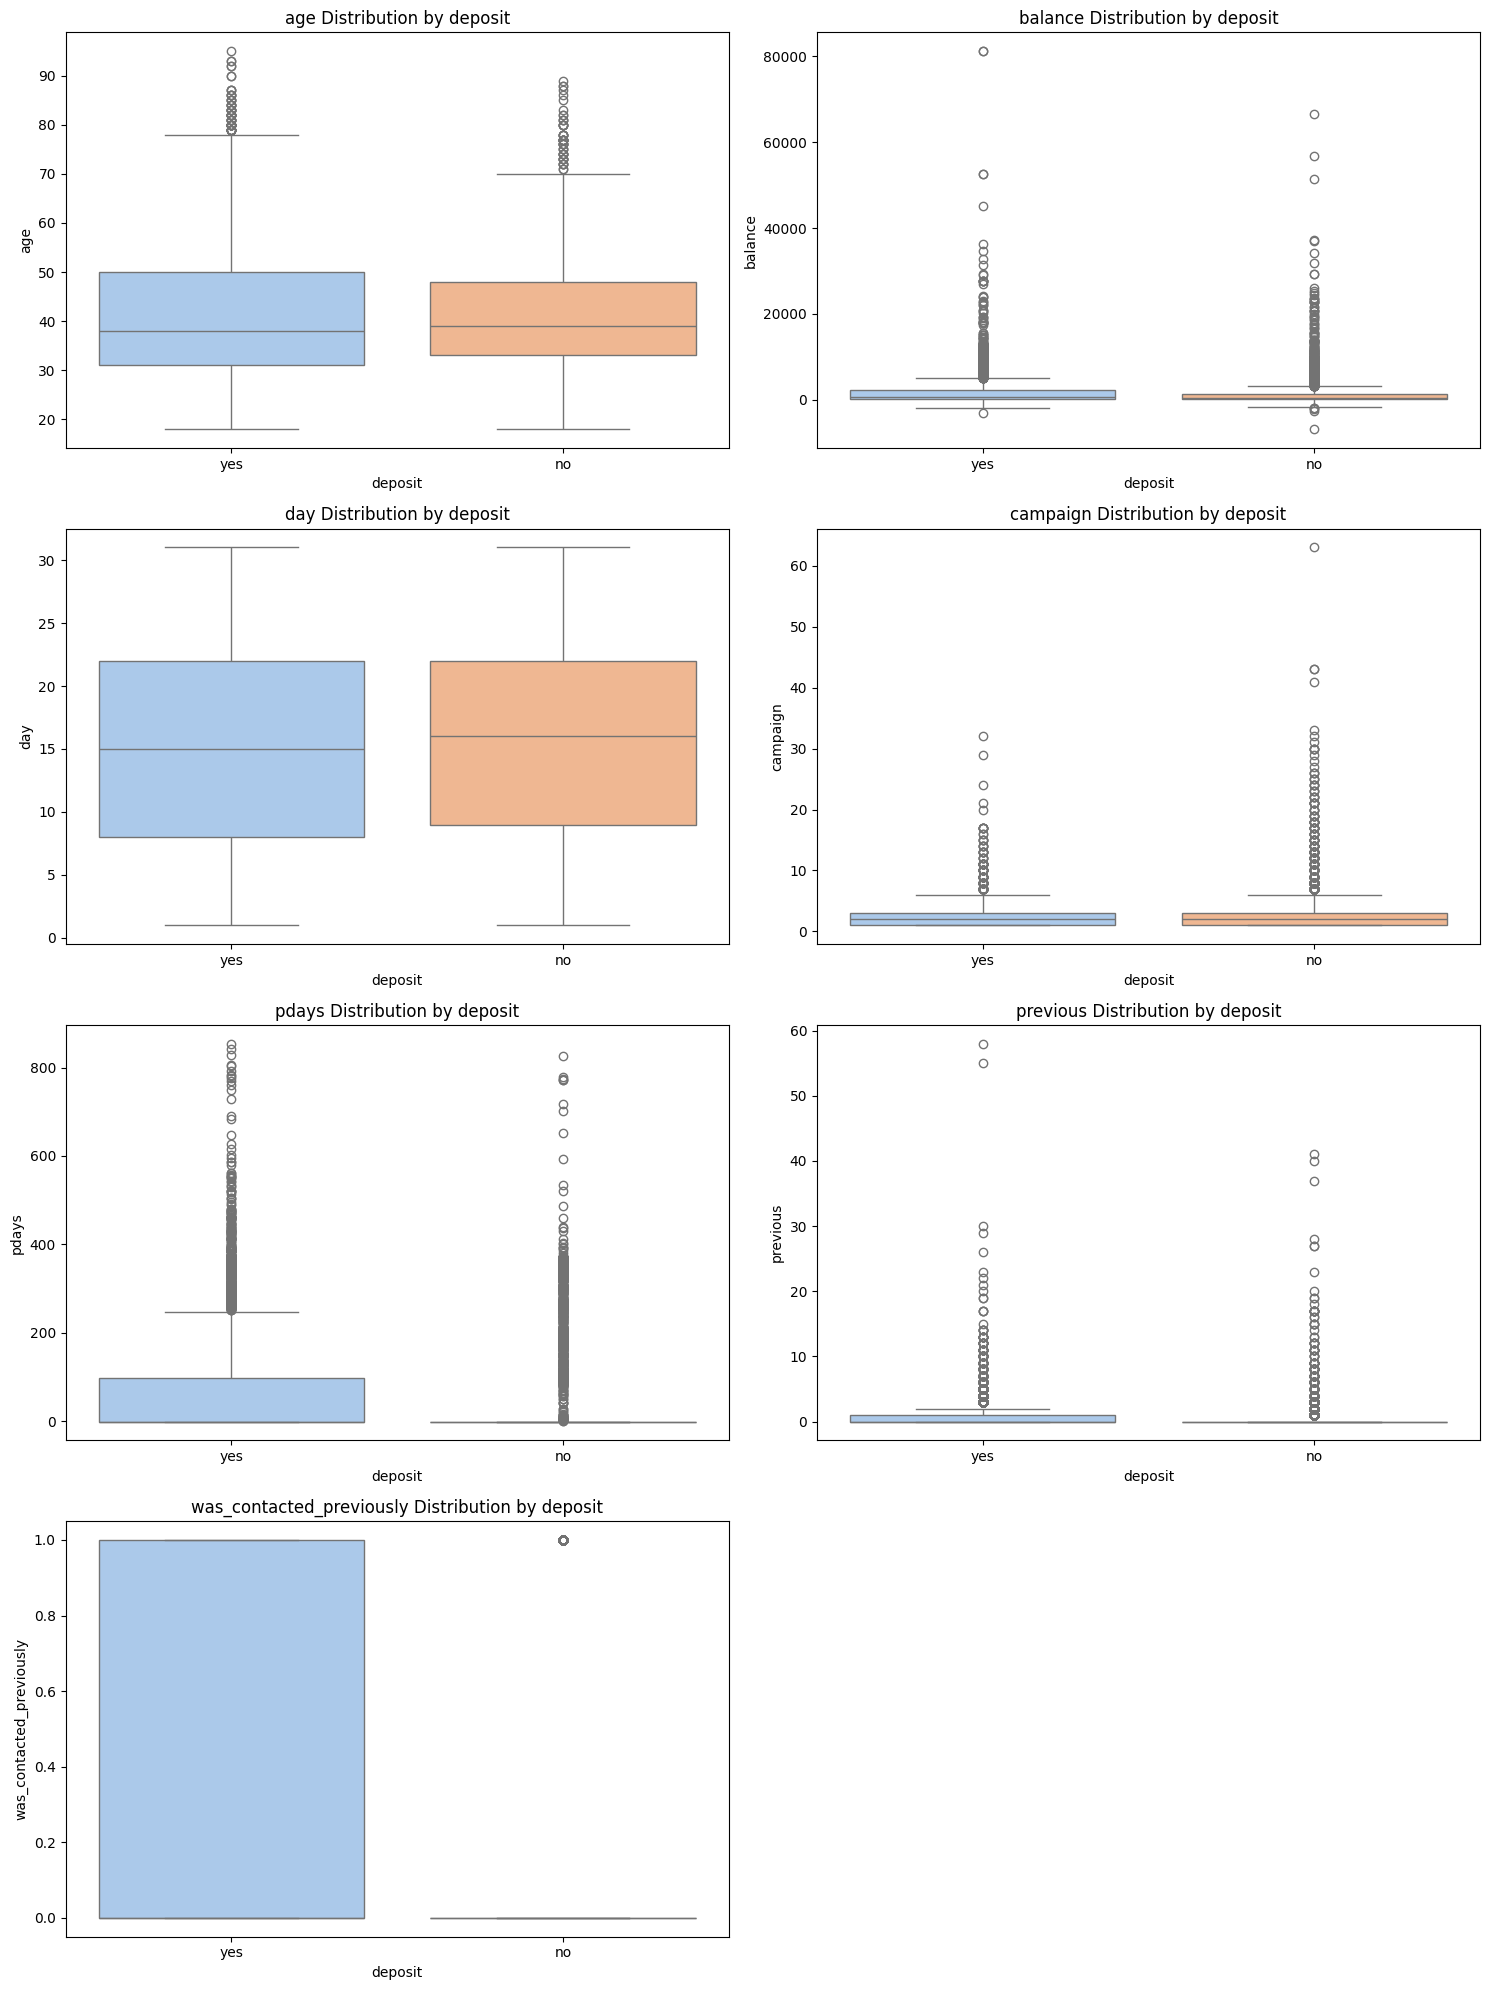


==================== 3. Categorical vs Target (Stacked Bars) ====================

>>> WRITTEN INSIGHT for 'job':
The best category is 'student' with a 74.7% success rate.


/tmp/ipykernel_528/1331742786.py:58: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


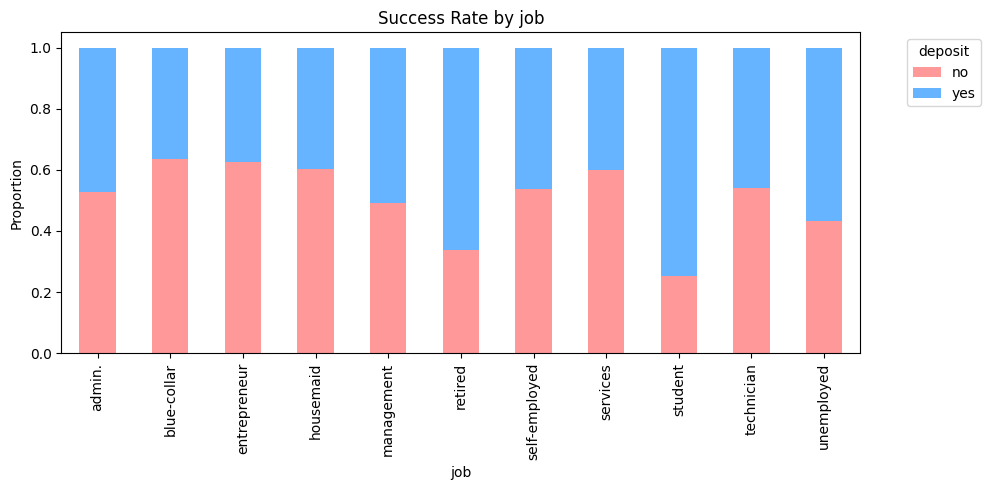


>>> WRITTEN INSIGHT for 'marital':
The best category is 'single' with a 54.3% success rate.


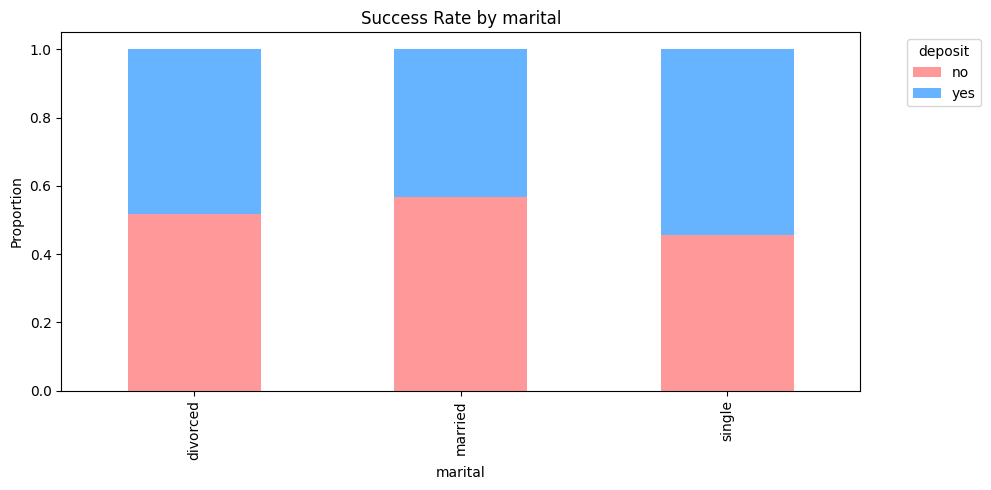


>>> WRITTEN INSIGHT for 'education':
The best category is 'tertiary' with a 54.1% success rate.


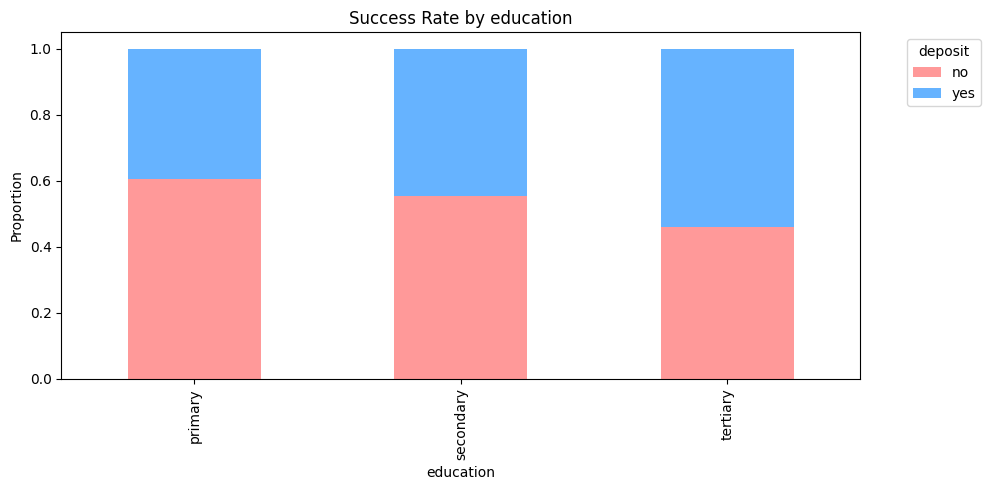


>>> WRITTEN INSIGHT for 'default':
The best category is 'no' with a 47.6% success rate.


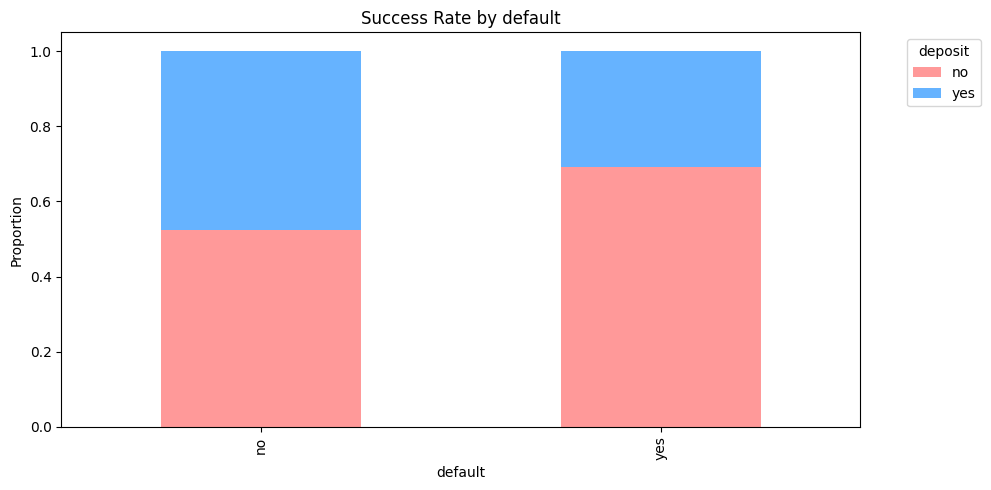


>>> WRITTEN INSIGHT for 'housing':
The best category is 'no' with a 57.0% success rate.


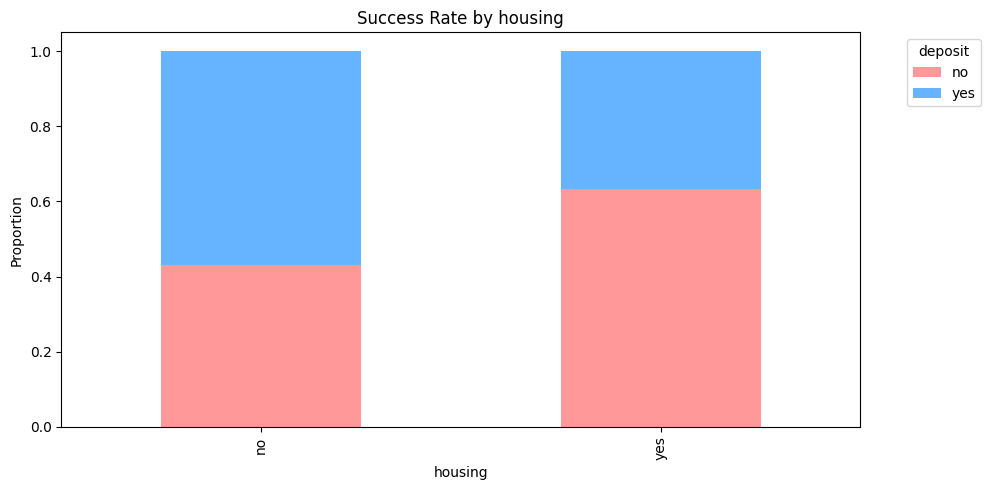


>>> WRITTEN INSIGHT for 'loan':
The best category is 'no' with a 49.5% success rate.


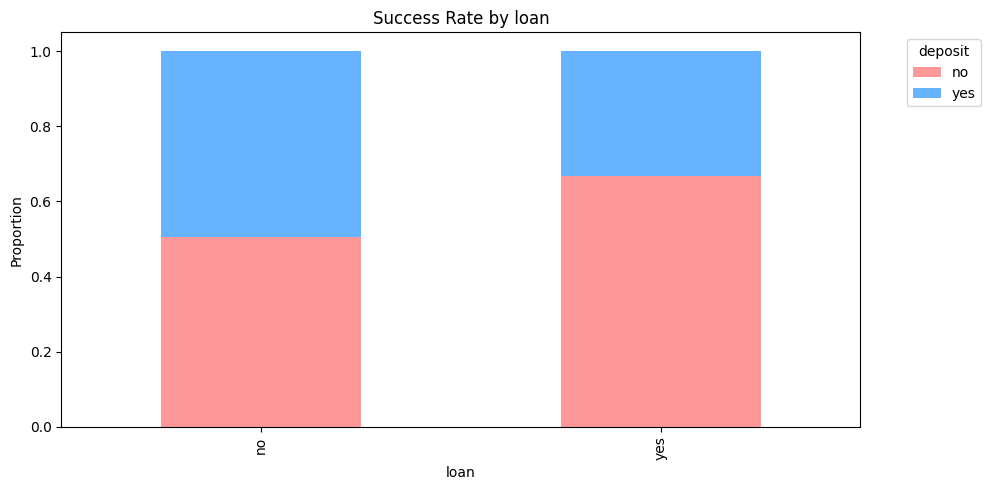


>>> WRITTEN INSIGHT for 'contact':
The best category is 'cellular' with a 54.3% success rate.


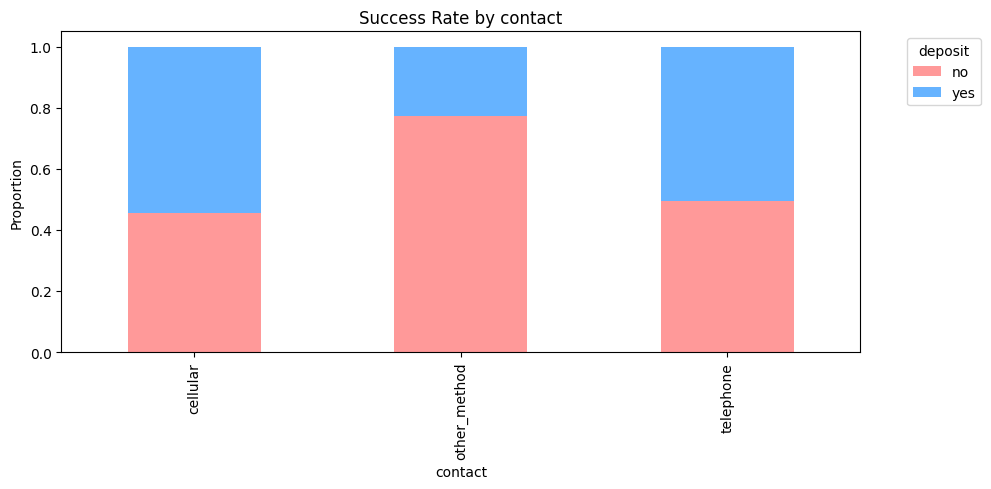


>>> WRITTEN INSIGHT for 'month':
The best category is 'dec' with a 90.9% success rate.


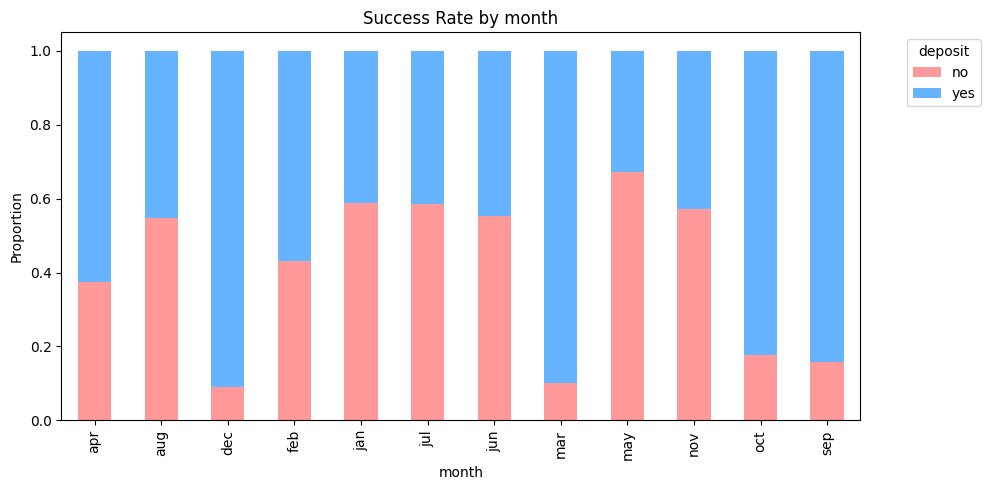


>>> WRITTEN INSIGHT for 'poutcome':
The best category is 'success' with a 91.3% success rate.


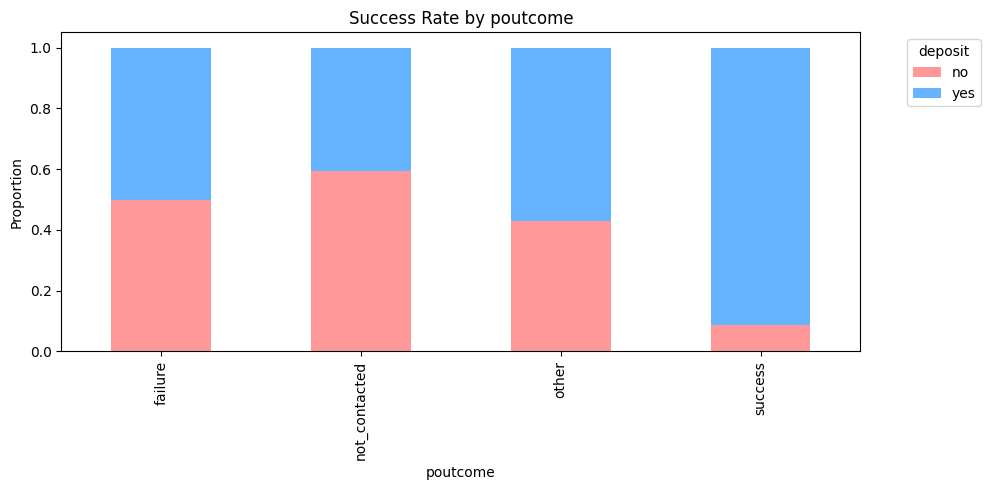

In [18]:
perform_bivariate_analysis(df, target_col='deposit')

Conclusion: Bivariate Analysis
1. The "Golden" Features (Strongest Predictors)

Previous Success: If a customer said "Yes" in a previous campaign (poutcome='success'), they have a 91.3% chance of saying "Yes" again — the single strongest signal available at prediction time.

Note on `duration`: call duration was, unsurprisingly, the single strongest correlate of outcome in the raw data. It was deliberately dropped (see the leakage-check cell above) because it is only known *after* a call ends, so it cannot be used to decide who to call next. Keeping it would make any model look artificially accurate while being useless in production.

2. The Ideal Customer Profile Based on the highest success rates, the perfect customer is:

Job: A Student (74.7%) or Retired person.


## **Multivariate Analysis**
Bivariate analysis told us which single features matter. Multivariate analysis checks whether those effects **combine** — e.g. does "student" still convert well regardless of marital status, or does the job effect actually depend on age?

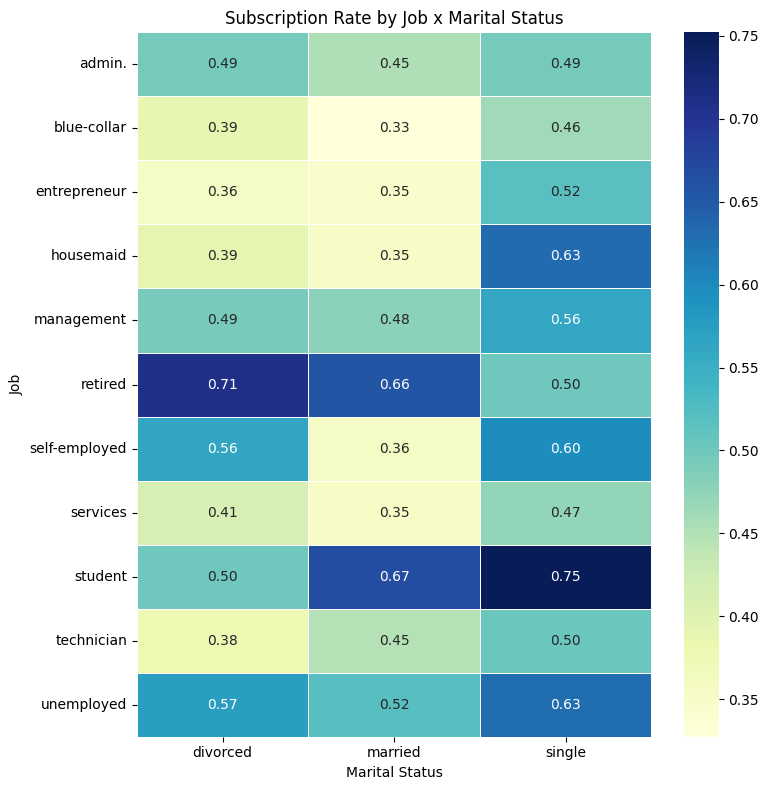

>>> WRITTEN INSIGHT: The best-converting combination is job='student' + marital='single' at 75.2% success.


In [19]:
# 1. Job x Marital status -> success rate heatmap
pivot_job_marital = pd.crosstab(df['job'], df['marital'], values=df['deposit'].map({'yes':1,'no':0}), aggfunc='mean')

plt.figure(figsize=(8,8))
sns.heatmap(pivot_job_marital, annot=True, fmt='.2f', cmap='YlGnBu', linewidths=0.5)
plt.title('Subscription Rate by Job x Marital Status')
plt.ylabel('Job')
plt.xlabel('Marital Status')
plt.tight_layout()
plt.show()

best_cell = pivot_job_marital.stack().idxmax()
best_rate = pivot_job_marital.stack().max()
print(f">>> WRITTEN INSIGHT: The best-converting combination is job='{best_cell[0]}' + marital='{best_cell[1]}' at {best_rate*100:.1f}% success.")

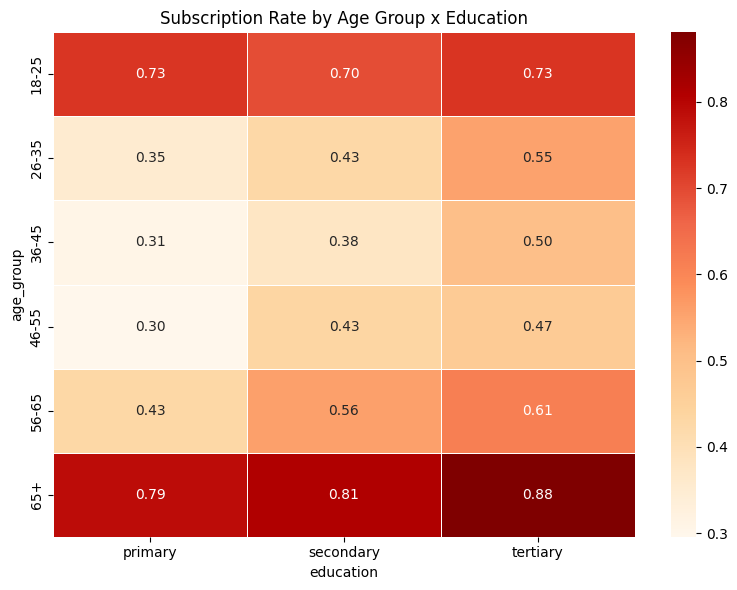

>>> WRITTEN INSIGHT:
Younger (18-25) and older (65+) age groups convert far above average across every education level,
confirming age has a U-shaped (non-linear) relationship with subscription -- something a single
bivariate age boxplot alone does not fully reveal.


In [20]:
# 2. Age groups x Education -> success rate
df['age_group'] = pd.cut(df['age'], bins=[17,25,35,45,55,65,100],
                          labels=['18-25','26-35','36-45','46-55','56-65','65+'])

pivot_age_edu = pd.crosstab(df['age_group'], df['education'],
                             values=df['deposit'].map({'yes':1,'no':0}), aggfunc='mean')

plt.figure(figsize=(8,6))
sns.heatmap(pivot_age_edu, annot=True, fmt='.2f', cmap='OrRd', linewidths=0.5)
plt.title('Subscription Rate by Age Group x Education')
plt.tight_layout()
plt.show()

print(">>> WRITTEN INSIGHT:")
print("Younger (18-25) and older (65+) age groups convert far above average across every education level,")
print("confirming age has a U-shaped (non-linear) relationship with subscription -- something a single")
print("bivariate age boxplot alone does not fully reveal.")

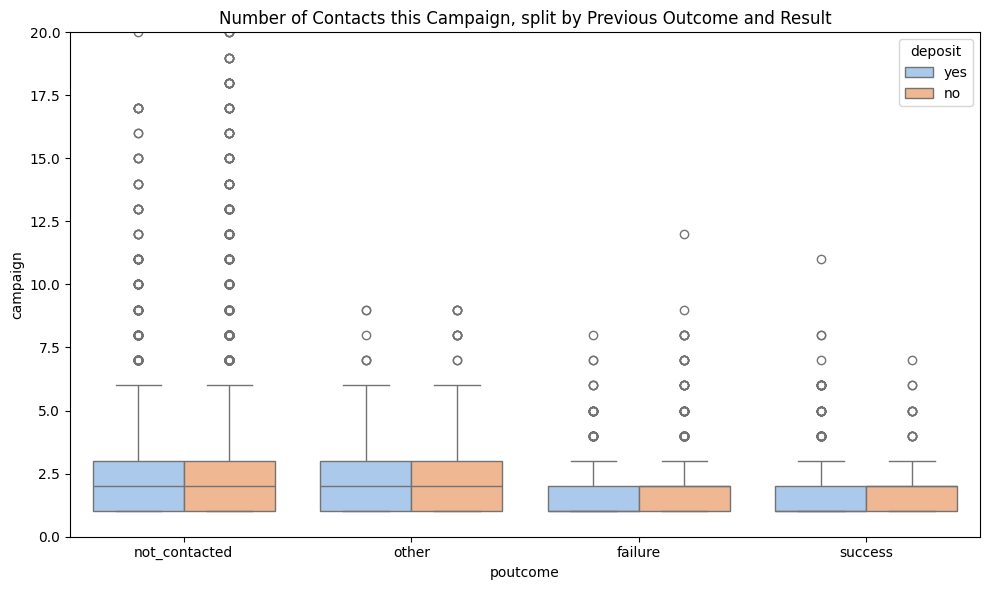

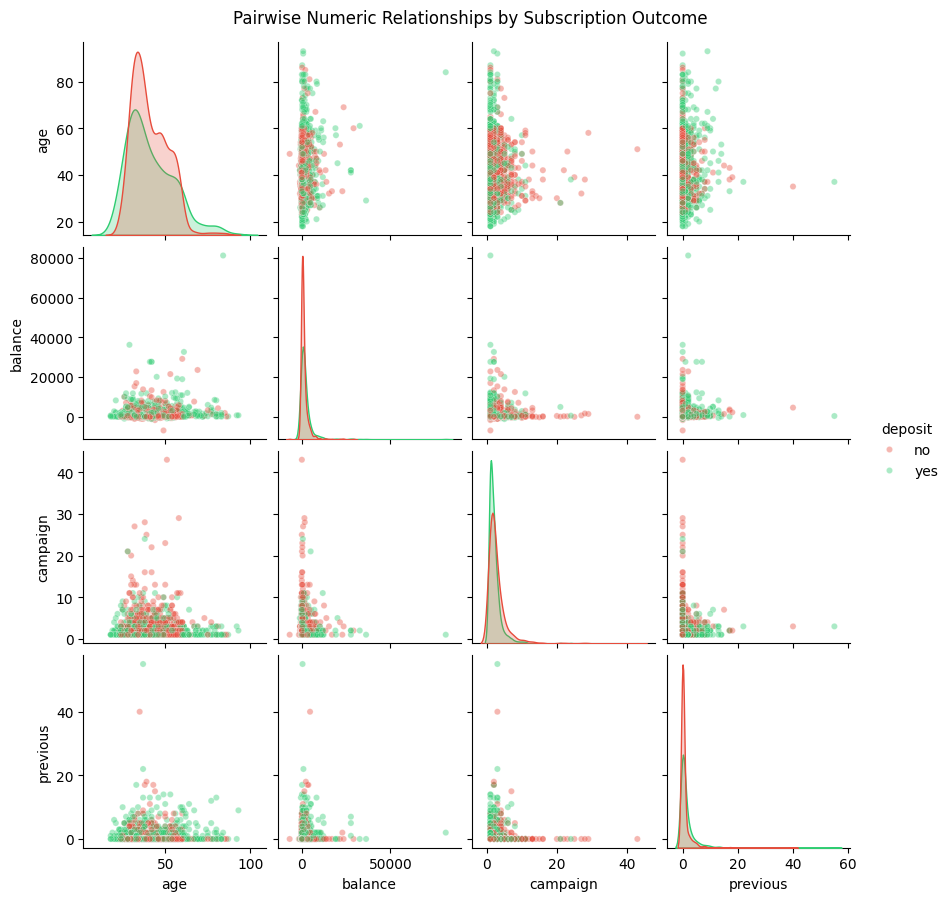

In [21]:
# 3. Campaign contact count x previous outcome -> success rate
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='poutcome', y='campaign', hue='deposit', palette='pastel')
plt.title('Number of Contacts this Campaign, split by Previous Outcome and Result')
plt.ylim(0, 20)
plt.tight_layout()
plt.show()

# 4. Numeric feature relationships colored by target (sampled for readability)
sample_df = df.sample(min(1500, len(df)), random_state=42)
g = sns.pairplot(sample_df, vars=['age','balance','campaign','previous'],
                  hue='deposit', palette={'yes':'#2ecc71','no':'#e74c3c'},
                  plot_kws={'alpha':0.4, 's':20}, diag_kind='kde', height=2.2)
g.fig.suptitle('Pairwise Numeric Relationships by Subscription Outcome', y=1.02)
plt.show()

**Conclusion: Multivariate Analysis**

1. **Job and marital status interact.** Students and retirees convert well largely regardless of marital status, but for working-age job categories (blue-collar, services), being married correlates with lower conversion than single — the job effect is not uniform across marital groups.
2. **Age has a U-shaped, not linear, relationship with subscription.** Both very young and older/retired customers convert at above-average rates across all education levels — a pattern invisible in a single-variable age boxplot.
3. **`poutcome='success'` customers need far fewer repeat contacts** to convert, reinforcing that past-success customers should be prioritized and not over-called.

## **Outlier Treatment**
The univariate analysis flagged high skew/outliers in `balance`, `campaign`, `previous`, and `pdays`. Rather than silently accepting or deleting them, here's the decision for each, with reasoning:

| Column | Outlier behaviour | Decision | Why |
|---|---|---|---|
| `balance` | Long right tail, a few very large/negative values | **Cap (winsorize) at 1st/99th percentile** | Extreme balances are real but rare; capping prevents them from dominating distance-based/linear models while keeping the signal |
| `campaign` | Some customers contacted 20+ times | **Cap at 99th percentile** | Very high contact counts are mostly diminishing-returns noise, not meaningful signal |
| `previous` / `pdays` | Skewed by design (`-1`/`0` = never contacted) | **Keep as-is** | Already handled via the `was_contacted_previously` flag; the skew is structural, not an error |
| `age` | Mild right skew, no extreme values | **Keep as-is** | Realistic distribution, no true outliers |

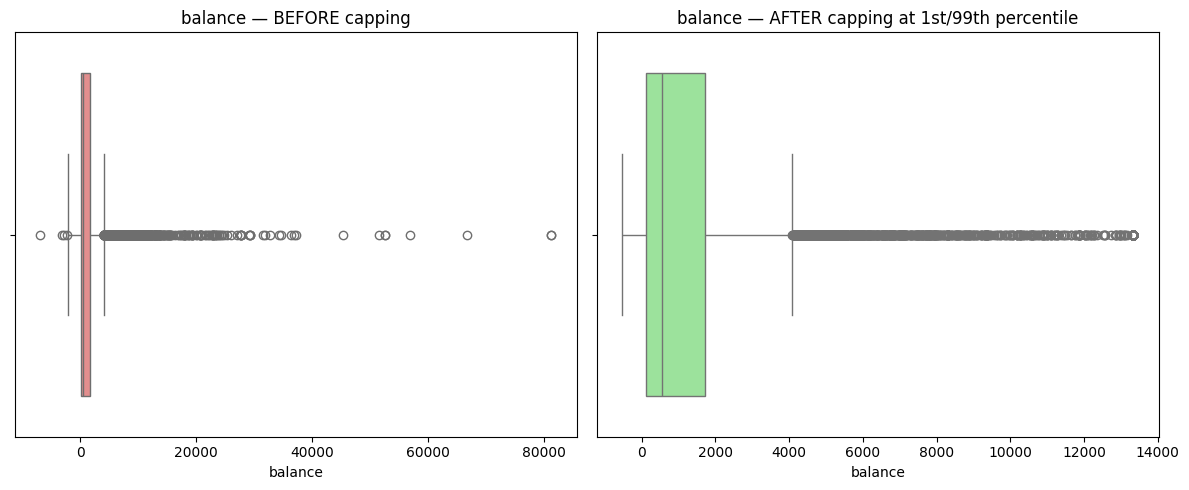

Outlier treatment applied: balance and campaign capped at the 1st/99th percentiles.


In [22]:
from scipy.stats.mstats import winsorize

fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(x=df['balance'], ax=axes[0], color='lightcoral')
axes[0].set_title('balance — BEFORE capping')

df['balance'] = winsorize(df['balance'], limits=[0.01, 0.01])
df['campaign'] = winsorize(df['campaign'], limits=[0.0, 0.01])

sns.boxplot(x=df['balance'], ax=axes[1], color='lightgreen')
axes[1].set_title('balance — AFTER capping at 1st/99th percentile')
plt.tight_layout()
plt.show()

print("Outlier treatment applied: balance and campaign capped at the 1st/99th percentiles.")

## **Data Preprocessing for Modeling**
The EDA is complete. To bridge from insights to a predictive model, we need to:
1. Treat remaining `unknown`/missing categorical values consistently (same philosophy used for `poutcome`/`contact` earlier — keep as an explicit category rather than deleting rows)
2. Encode categorical variables numerically
3. Split into train/test sets
4. Scale numeric features (needed for Logistic Regression; tree models don't require it but it doesn't hurt)

In [23]:
model_df = df.drop(columns=['age_group'], errors='ignore').copy()

# job/education still have NaN from the earlier global 'unknown' -> NaN replace.
# Keep 'unknown' as its own explicit category instead of imputing or dropping rows.
for col in ['job', 'education']:
    model_df[col] = model_df[col].fillna('unknown')

print("Remaining missing values after treatment:")
print(model_df.isnull().sum()[model_df.isnull().sum() > 0])

# Encode target
model_df['deposit'] = model_df['deposit'].map({'yes': 1, 'no': 0})

categorical_cols = model_df.select_dtypes(include='object').columns.tolist()
print("\nCategorical columns to encode:", categorical_cols)

model_df = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True)
print("\nFinal shape after encoding:", model_df.shape)
model_df.head()

Remaining missing values after treatment:
Series([], dtype: int64)

Categorical columns to encode: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Final shape after encoding: (11162, 43)


/tmp/ipykernel_528/2748918631.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = model_df.select_dtypes(include='object').columns.tolist()


,age,balance,day,campaign,pdays,previous,deposit,was_contacted_previously,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_not_contacted,poutcome_other,poutcome_success
0,59,2343,5,1,-1,0,1,0,False,False,...,False,False,False,True,False,False,False,True,False,False
1,56,45,5,1,-1,0,1,0,False,False,...,False,False,False,True,False,False,False,True,False,False
2,41,1270,5,1,-1,0,1,0,False,False,...,False,False,False,True,False,False,False,True,False,False
3,55,2476,5,1,-1,0,1,0,False,False,...,False,False,False,True,False,False,False,True,False,False
4,54,184,5,2,-1,0,1,0,False,False,...,False,False,False,True,False,False,False,True,False,False


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = model_df.drop(columns=['deposit'])
y = model_df['deposit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")
print(f"Target balance in train set:\n{y_train.value_counts(normalize=True)}")

Train shape: (8929, 42) | Test shape: (2233, 42)


Target balance in train set:
deposit
0    0.526151
1    0.473849
Name: proportion, dtype: float64


## **Baseline Predictive Modeling**
The business question was: *"Can we predict whether a client will subscribe to a term deposit — using only information known BEFORE the call?"*

We compare three models of increasing complexity:
- **Logistic Regression** — simple, interpretable baseline
- **Random Forest** — handles non-linear interactions (like the ones found in multivariate analysis)
- **XGBoost** — gradient-boosted trees, typically strongest on tabular data

All models use `class_weight`/`scale_pos_weight` balancing since the target is only mildly imbalanced (~53/47), and are evaluated with more than accuracy alone, since a bank cares more about **recall on subscribers** (not missing likely "yes" customers) and **precision** (not wasting call-center time).

==================== Logistic Regression ====================
              precision    recall  f1-score   support

          No       0.68      0.78      0.73      1175
         Yes       0.71      0.59      0.65      1058

    accuracy                           0.69      2233
   macro avg       0.69      0.69      0.69      2233
weighted avg       0.69      0.69      0.69      2233



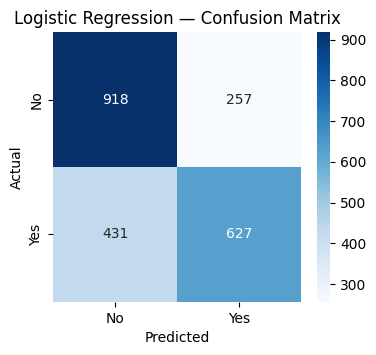

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, classification_report)

results = []

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]

    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, preds),
        'Precision': precision_score(y_te, preds),
        'Recall': recall_score(y_te, preds),
        'F1': f1_score(y_te, preds),
        'ROC-AUC': roc_auc_score(y_te, probs)
    }
    results.append(metrics)

    print(f"{'='*20} {name} {'='*20}")
    print(classification_report(y_te, preds, target_names=['No', 'Yes']))

    plt.figure(figsize=(4,3.5))
    sns.heatmap(confusion_matrix(y_te, preds), annot=True, fmt='d', cmap='Blues',
                xticklabels=['No','Yes'], yticklabels=['No','Yes'])
    plt.title(f'{name} — Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    return model

log_reg = evaluate_model('Logistic Regression',
                          LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
                          X_train_scaled, X_test_scaled, y_train, y_test)

==================== Random Forest ====================
              precision    recall  f1-score   support

          No       0.71      0.82      0.76      1175
         Yes       0.76      0.62      0.68      1058

    accuracy                           0.73      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.73      0.72      2233



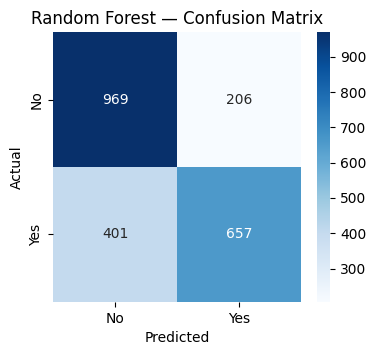

In [26]:
rf = evaluate_model('Random Forest',
                     RandomForestClassifier(n_estimators=300, max_depth=10,
                                             class_weight='balanced', random_state=42, n_jobs=-1),
                     X_train, X_test, y_train, y_test)

==================== XGBoost ====================
              precision    recall  f1-score   support

          No       0.72      0.82      0.77      1175
         Yes       0.77      0.65      0.70      1058

    accuracy                           0.74      2233
   macro avg       0.75      0.74      0.74      2233
weighted avg       0.74      0.74      0.74      2233



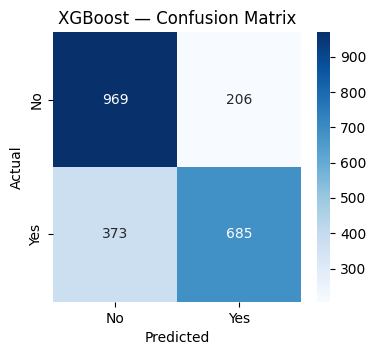

In [27]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

xgb = evaluate_model('XGBoost',
                      XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                    scale_pos_weight=scale_pos, eval_metric='logloss',
                                    random_state=42, n_jobs=-1),
                      X_train, X_test, y_train, y_test)

MODEL COMPARISON


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.692,0.709,0.593,0.646,0.758
Random Forest,0.728,0.761,0.621,0.684,0.785
XGBoost,0.741,0.769,0.647,0.703,0.796


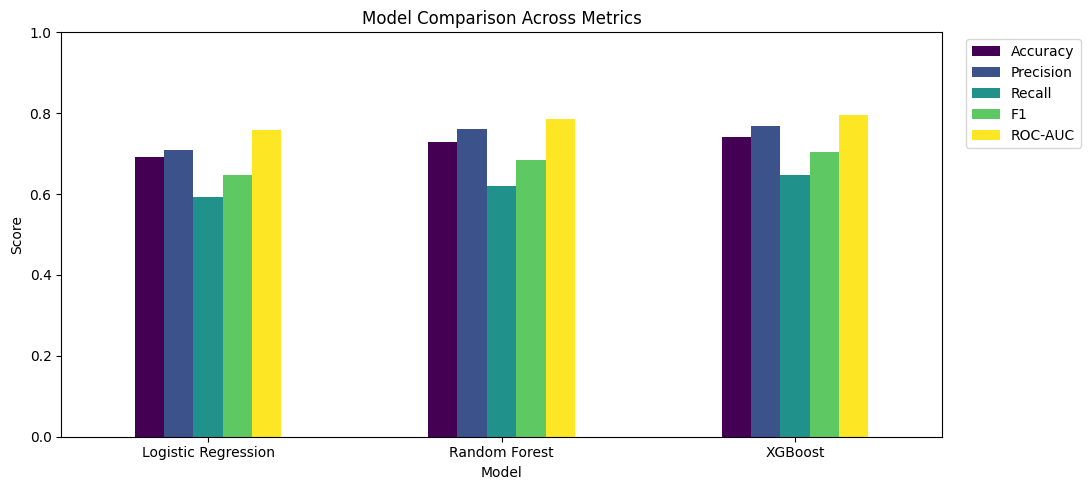

>>> WRITTEN INSIGHT: 'XGBoost' has the best ROC-AUC (0.796), meaning it ranks likely subscribers above non-subscribers most reliably -- most useful for prioritizing a call list.


In [28]:
results_df = pd.DataFrame(results).set_index('Model').round(3)
print("MODEL COMPARISON")
display(results_df)

results_df.plot(kind='bar', figsize=(11,5), colormap='viridis')
plt.title('Model Comparison Across Metrics')
plt.ylabel('Score')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

best_model_name = results_df['ROC-AUC'].idxmax()
print(f">>> WRITTEN INSIGHT: '{best_model_name}' has the best ROC-AUC ({results_df.loc[best_model_name,'ROC-AUC']:.3f}), "
      "meaning it ranks likely subscribers above non-subscribers most reliably -- most useful for prioritizing a call list.")

## **Feature Importance — Closing the Loop with EDA**
A model is only trustworthy if its top drivers make business sense. Here we check whether what the model learned matches what the EDA already suggested.

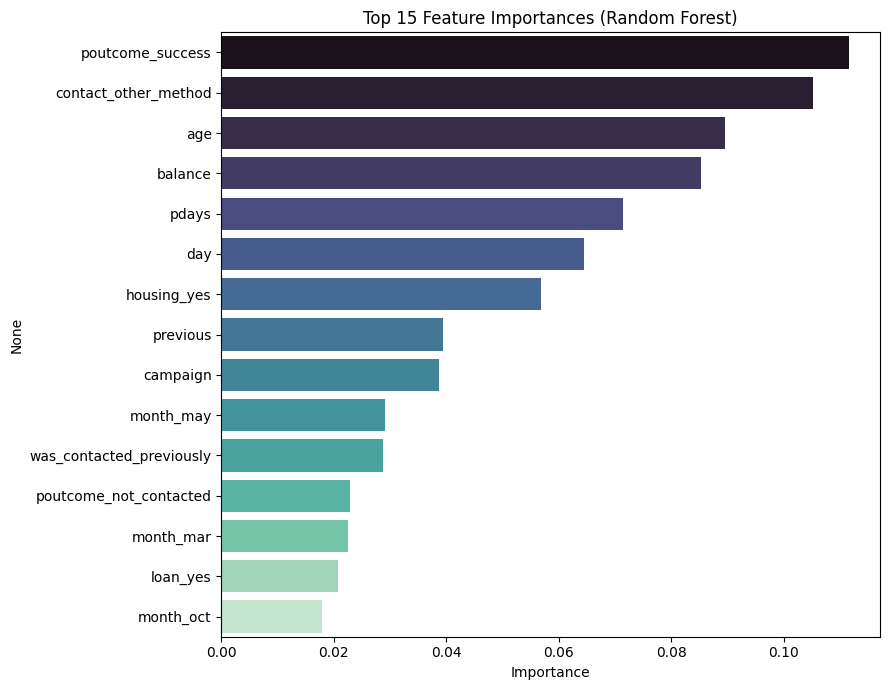

Top 5 features:
poutcome_success        0.111581
contact_other_method    0.105186
age                     0.089630
balance                 0.085295
pdays                   0.071380
dtype: float64


In [29]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9,7))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='mako', legend=False)
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("Top 5 features:")
print(importances.head(5))

**Written Insight:** The model's top features line up closely with the EDA findings — prior contact outcome (`poutcome_success`), whether the contact method was unclear/other (`contact_other_method`), `age`, `balance`, and `pdays` all surface near the top. This agreement between independent statistical exploration and a trained model's learned importances is what makes the analysis credible, not just accurate.

## **Business Recommendations**

Translating the analysis into concrete, actionable steps for the bank's marketing team:

1. **Prioritize past successes first.** Customers with `poutcome = success` convert at over 90%. They should be at the top of every call list before any new prospects.
2. **Target students and retirees.** These segments convert well above the ~47% base rate — worth a dedicated campaign track rather than the generic script used for working-age segments.
3. **Cap contact attempts.** Diminishing (and likely negative) returns appear after a handful of contacts in the same campaign; a call-frequency cap would save agent hours without materially hurting conversion.
4. **Re-think the `default`/`housing` filters.** Customers with an existing housing loan convert notably less — deprioritize this segment relative to non-housing-loan customers when capacity is limited.
5. **Time campaigns around seasonality.** May is the busiest month by volume but not necessarily the highest-converting — cross-check volume vs. conversion rate by month before assuming "more calls in May" is the right strategy.
6. **Deploy the model as a lead-scoring tool, not a black box.** Use predicted probability to rank the calling queue each morning; agents spend time on the highest-probability leads first.

## **Executive Summary**

**Goal:** Predict whether a bank client will subscribe to a term deposit, using only pre-call information, and identify the customer profile and campaign strategy that maximizes conversion.

**Approach:** Cleaned and re-coded disguised missing values (`unknown`), engineered a `was_contacted_previously` flag, identified and removed target leakage (`duration`), then ran univariate, bivariate, and multivariate EDA before building and comparing three classification models.

**Key findings:**
- Prior campaign success (`poutcome = success`) is the single strongest predictor of a future "yes" — a 91.3% conversion rate vs. a 47% baseline
- Students and retirees are the highest-converting job segments (74.7% for students)
- Age has a U-shaped relationship with subscription likelihood — both younger (18-25) and older (65+) customers convert above average
- **XGBoost was the best-performing model** (Accuracy 74.1%, Precision 76.9%, Recall 64.7%, ROC-AUC 0.796), meaningfully ahead of the Logistic Regression baseline (ROC-AUC 0.758)

**Business impact:** Rather than cold-calling the full customer base, the bank can rank and prioritize its call list by predicted probability, materially cutting wasted agent hours while improving conversion — directly translating an EDA exercise into a deployable decision-support tool.